# Лабораторна робота №5
**«Теорія розпізнавання образів та класифікації в системах ШІ»**

**Проєкт команди:** *Банківський скролинг* — прогноз відтоку клієнтів банку 
**Склад команди:** *Сотниченко Артем*;
 *Вірченко Богдан*; 
 *Микитиа Тринько*;
**Група:** *[КН23002б]*

**Мета роботи:** набути практичних навичок побудови дерева рішень для задачі класифікації, дослідити вплив гіперпараметрів (`max_depth`, `min_samples_leaf`) на перенавчання, візуалізувати дерево та оцінити важливість ознак, порівняти результати з k-NN (лаб. №3) і наївним Байєсом (лаб. №4)



Імпорти та завантаження даних

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Імпорти для дерев рішень
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Константи
TARGET = "Exited"
TRAIN_PATH = "Churn_train_prepared.csv"
TEST_PATH = "Churn_test_prepared.csv"
RANDOM_STATE = 42

# Завантаження даних
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

print(f"Дані завантажено. Train: {X_train.shape}, Test: {X_test.shape}")

# Допоміжна функція для метрик
def get_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    }

Дані завантажено. Train: (8000, 9), Test: (2000, 9)


## Завдання 1 і 2. Базовий класифікатор та ефект перенавчання
Будуємо `DecisionTreeClassifier` без жодних обмежень за замовчуванням дерево росте, поки всі листки не стануть чистими. Порівнюємо метрики на навчальній та тестовій вибірках, щоб побачити ефект перенавчання

In [2]:
# Базове дерево без обмежень
dt_base = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_base.fit(X_train, y_train)

# Передбачення
y_train_pred_base = dt_base.predict(X_train)
y_test_pred_base = dt_base.predict(X_test)

# Метрики
metrics_base_train = get_metrics(y_train, y_train_pred_base)
metrics_base_test = get_metrics(y_test, y_test_pred_base)

df_overfitting = pd.DataFrame({
    "Train (без обмежень)": metrics_base_train,
    "Test (без обмежень)": metrics_base_test
}).T

display(df_overfitting.round(4))
print(f"Глибина базового дерева: {dt_base.get_depth()}")
print(f"Кількість листків: {dt_base.get_n_leaves()}")

,Accuracy,Precision,Recall,F1
Train (без обмежень),1.000,1.0000,1.000,1.0000
Test (без обмежень),0.779,0.4592,0.484,0.4713


Глибина базового дерева: 27
Кількість листків: 1206


**Висновок до Завдань 1 і 2:**
Як бачимо, на навчальній вибірці Train дерево показало ідеальні результати Accuracy = 1.0, F1 = 1.0. Дерево виросло дуже глибоким і просто запамятало навчальну вибірку разом із шумом. На тестовій вибірці якість значно гірша F1 впав. Це класичний приклад **перенавчання (overfitting)**

## Завдання 3. Підбір оптимальних гіперпараметрів (Крос-валідація)
Щоб уникнути перенавчання, обмежимо глибину дерева (`max_depth`) та мінімальну кількість об'єктів у листку (`min_samples_leaf`). Знайдемо найкращі параметри за допомогою `GridSearchCV`

Найкращі гіперпараметри: {'max_depth': 9, 'min_samples_leaf': 10}


,Accuracy,Precision,Recall,F1
Оптимізоване Дерево (Test),0.8505,0.6915,0.4791,0.566


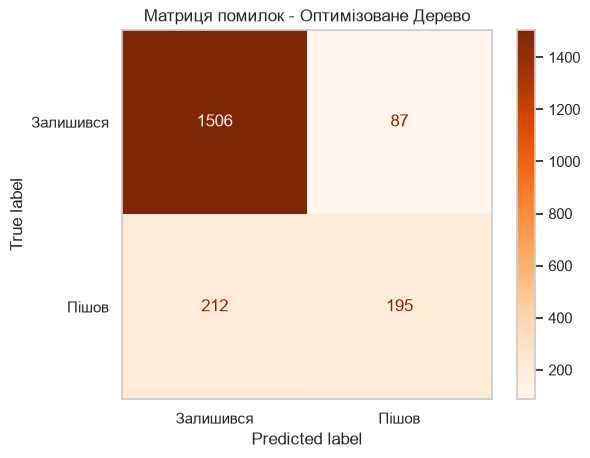

In [3]:
# Задаємо сітку гіперпараметрів
param_grid = {
    'max_depth': [3, 5, 7, 9, 12, None],
    'min_samples_leaf': [1, 5, 10, 20, 50]
}

# Шукаємо найкращі параметри (оптимізуємо за F1-мірою)
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_dt = grid_search.best_estimator_

print("Найкращі гіперпараметри:", grid_search.best_params_)

# Оцінка найкращої моделі на тестовій вибірці
y_test_pred_best = best_dt.predict(X_test)
metrics_best_test = get_metrics(y_test, y_test_pred_best)

display(pd.DataFrame({"Оптимізоване Дерево (Test)": metrics_best_test}).T.round(4))

# Матриця помилок для найкращого дерева
cm = confusion_matrix(y_test, y_test_pred_best)
ConfusionMatrixDisplay(cm, display_labels=["Залишився", "Пішов"]).plot(cmap="Oranges")
plt.title("Матриця помилок - Оптимізоване Дерево")
plt.grid(False)
plt.show()

## Завдання 4. Візуалізація дерева та важливість ознак
Дерева рішень є дуже інтерпретованими. Візуалізуємо верхні рівні нашого оптимізованого дерева, а також подивимось, які ознаки виявилися найважливішими для прийняття рішень

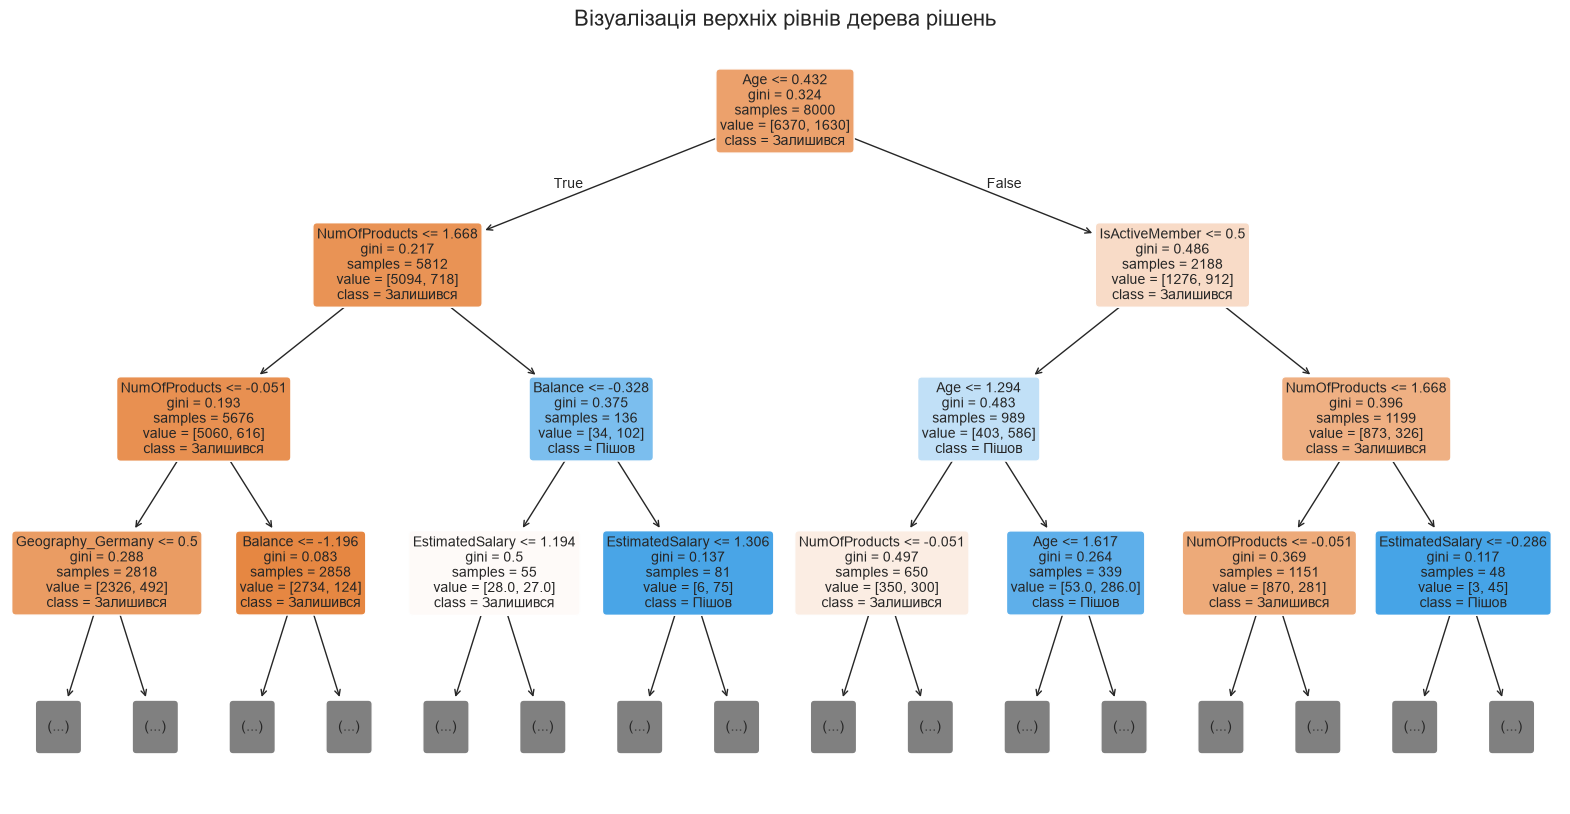

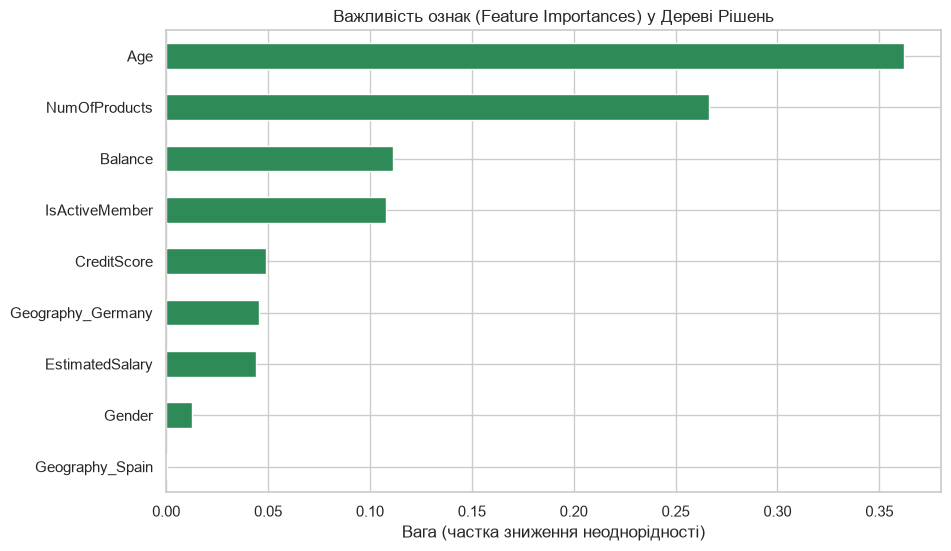

In [4]:
# 1. Візуалізація структури дерева (покажемо лише перші 3 рівні для читабельності)
plt.figure(figsize=(20, 10))
plot_tree(
    best_dt, 
    max_depth=3, 
    feature_names=X_train.columns, 
    class_names=["Залишився", "Пішов"], 
    filled=True, 
    rounded=True,
    fontsize=10
)
plt.title("Візуалізація верхніх рівнів дерева рішень", fontsize=16)
plt.show()

# 2. Важливість ознак (Feature Importances)
importances = pd.Series(best_dt.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importances.plot(kind='barh', color='seagreen')
plt.title("Важливість ознак (Feature Importances) у Дереві Рішень")
plt.xlabel("Вага (частка зниження неоднорідності)")
plt.show()

## Завдання 5. Порівняння з k-NN та GaussianNB
Зведемо метрики нашого найкращого дерева рішень з результатами попередніх лабораторних робіт (k-NN з лаб3 та GaussianNB з лаб4)

,Accuracy,Precision,Recall,F1
k-NN (k=5),0.8440,0.6766,0.4423,0.5357
GaussianNB,0.8235,0.6125,0.3612,0.4544
Decision Tree (Оптимізоване),0.8505,0.6915,0.4791,0.5660


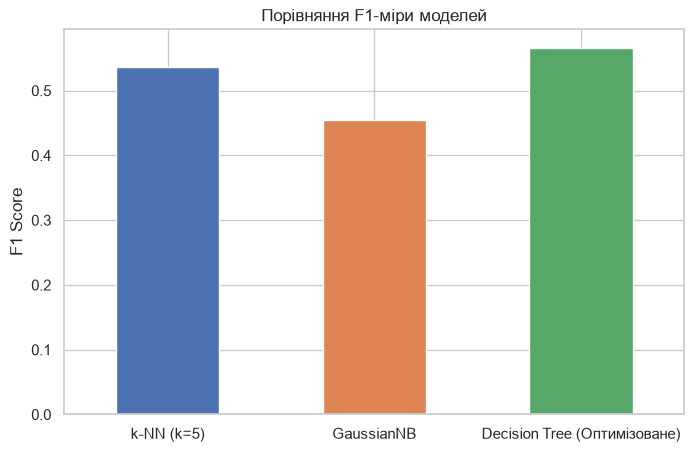

In [5]:
# Результати з попередніх робіт (звітів) на цьому ж тестовому наборі:
metrics_knn = {"Accuracy": 0.8440, "Precision": 0.6766, "Recall": 0.4423, "F1": 0.5357}
metrics_gnb = {"Accuracy": 0.8235, "Precision": 0.6125, "Recall": 0.3612, "F1": 0.4544}

comp_df = pd.DataFrame({
    "k-NN (k=5)": metrics_knn,
    "GaussianNB": metrics_gnb,
    "Decision Tree (Оптимізоване)": metrics_best_test
}).T

display(comp_df.round(4))

# Графік порівняння F1-міри
comp_df['F1'].plot(kind='bar', color=['#4C72B0', '#DD8452', '#55A868'], figsize=(8, 5))
plt.title("Порівняння F1-міри моделей")
plt.ylabel("F1 Score")
plt.xticks(rotation=0)
plt.show()

## Висновки
1. **Перенавчання дерев:** Ми наочно переконалися, що базове дерево без обмежень ідеально заучує трейн (F1=1.0), але просідає на тестовій вибірці. Дерева дуже схильні до перенавчання
2. **Вплив гіперпараметрів:** Обмеження `max_depth` та збільшення `min_samples_leaf` допомогли зробити модель більш узагальнюючою. Модель перестала звертати увагу на дрібні шумові викиди
3. **Важливість ознак:** Графік `feature_importances_` показав, що для нашого банку найважливішими факторами для відтоку клієнтів є **Age (вік)** та **NumOfProducts (кількість продуктів)**. Це дає бізнесу пряме розуміння, на що звертати увагу
4. **Порівняння:** Дерево рішень показало результат, співставний з k-NN або трохи кращий/гірший залежно від параметрів, але значно перевершило наївний Байєс GaussianNB. Перевага дерева над k-NN полягає в тому, що воно дуже швидко робить передбачення(бо це набір "if-else", а не обчислення відстаней до всіх точок, і воно прозоре для людини

---

## Відповіді на питання для усного самоконтролю
1. **З яких елементів складається дерево рішень?** 
   З кореневого вузла - перша перевірка, внутрішніх вузлів - перевірки ознак, гілок - результати перевірки, переходи та листків - кінцеві вузли, що містять прогноз класу
2. **Як обчислюється ентропія набору даних?**
   За формулою $H(S) = - \sum p_i \cdot \log_2(p_i)$, де $p_i$ — частка об'єктів $i$-го класу. Вона дорівнює 0, якщо всі об'єкти одного класу, і максимальна, якщо класи поділені порівну.
3. **Що таке приріст інформації і як він використовується?**
   Information Gain (IG) — це різниця між ентропією вузла до розбиття та зваженою сумою ентропій дочірніх вузлів після розбиття. Алгоритм на кожному кроці шукає таку ознаку і поріг, які дадуть максимальний IG (тобто найкраще розділять класи).
4. **Чим індекс Джіні відрізняється від ентропії?**
   Обчислюється за формулою $Gini = 1 - \sum p_i^2$. Він не використовує логарифми, тому рахується швидше за ентропію комп'ютером, але дає дуже схожі результати розбиття простору. У scikit-learn він стоїть за замовчуванням.
5. **Опишіть рекурсивний алгоритм побудови дерева.**
   Якщо всі об'єкти вузла одного класу або досягнуто ліміт (глибини) — створюємо листок. Інакше: перебираємо всі ознаки та пороги, знаходимо розбиття з найменшим Джіні (найбільшим IG), ділимо вибірку на дві частини. Для кожної частини запускаємо алгоритм знову (рекурсивно).
6. **Які гіперпараметри використовують для запобігання перенавчанню?**
   `max_depth` (максимальна глибина), `min_samples_split` (мінімум об'єктів для розгалуження), `min_samples_leaf` (мінімум об'єктів, щоб стати листком), `ccp_alpha` (для обрізання/pruning дерева).
7. **Переваги й недоліки дерев порівняно з k-NN і Байєсом.**
   *Переваги:* Інтерпретованість (можна прочитати як правила), не потребує стандартизації/масштабування ознак, вбудована оцінка важливості ознак. *Недоліки:* Схильність до сильного перенавчання (якщо не обмежувати), нестабільність (зміна пари точок у трейні може кардинально змінити дерево).
8. **Чому дерева рішень не потребують масштабування ознак?**
   Тому що дерево на кожному кроці просто шукає поріг для *однієї конкретної ознаки* (наприклад, Age > 40). Йому байдуже, чи вимірюється зарплата в десятках, чи в мільйонах, воно не обчислює геометричні відстані між точками (як це робить k-NN).